# Project Report Code Appendix: Task 1 - Handwritten Digit Recognition
- **Course Code:** DLMDSWCV01 
- **Student Name:** Saifullah Safiyanu
- **Matriculation Number:** 92132129
- **Institution:** IU International University of Applied Sciences
- **Project Purpose:** This notebook contains the implementation, training, evaluation, and comparative analysis of François Chollet's modern baseline Convolutional Neural Network (Chollet, 2021) and its custom modification to approximate the historical CNN architecture introduced by Le Cun et al. (1989).

In [2]:
# ==========================================
# 1. SETUP AND LIBRARIES
# ==========================================
import numpy as np
import keras
from keras import layers
import matplotlib.pyplot as plt

print("Environment setup complete. Keras version:", keras.__version__)

Environment setup complete. Keras version: 3.15.1


In [3]:
# ==========================================
# 2. DATA PREPARATION: MNIST DATASET
# Description: The MNIST dataset consists of 60,000 training images 
# and 10,000 test images of normalized 28x28 grayscale handwritten digits (0-9).
# ==========================================
num_classes = 10
input_shape = (28, 28, 1)

# Load data (Original framework)
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

# Scale pixel values to the [0, 1] range (Original framework)
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Ensure proper channel dimensions for Conv2D layers
x_train = np.expand_dims(x_train, -1)
x_test = np.expand_dims(x_test, -1)

# Convert class vectors to binary class matrices (one-hot encoding)
y_train = keras.utils.to_categorical(y_train, num_classes)
y_test = keras.utils.to_categorical(y_test, num_classes)

print("Training data shape:", x_train.shape)
print("Test data shape:", x_test.shape)

Training data shape: (60000, 28, 28, 1)
Test data shape: (10000, 28, 28, 1)


In [4]:
# ==========================================
# 3. ORIGINAL BASELINE MODEL
# Source: Adapted from François Chollet's "Simple MNIST convnet" (Chollet, 2021).
# ==========================================
model_baseline = keras.Sequential(
    [
        keras.Input(shape=input_shape),
        layers.Conv2D(32, kernel_size=(3, 3), activation="relu"),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Conv2D(64, kernel_size=(3, 3), activation="relu"),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Flatten(),
        layers.Dropout(0.5),
        layers.Dense(num_classes, activation="softmax"),
    ],
    name="Chollet_Baseline"
)

model_baseline.summary()

# Training Baseline
model_baseline.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
history_baseline = model_baseline.fit(x_train, y_train, batch_size=128, epochs=15, validation_split=0.1, verbose=1)

# Evaluating Baseline
score_baseline = model_baseline.evaluate(x_test, y_test, verbose=0)
print(f"Baseline Test Loss: {score_baseline[0]:.4f}")
print(f"Baseline Test Accuracy: {score_baseline[1]*100:.2f}%")

Model: "Chollet_Baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 1600)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 1600)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 10)                  │          16,010 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 34,826 (136.04 KB)

 Trainable params: 34,826 (136.04 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 18s 38ms/step - accuracy: 0.8847 - loss: 0.3774 - val_accuracy: 0.9770 - val_loss: 0.0868
Epoch 2/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 19s 45ms/step - accuracy: 0.9667 - loss: 0.1124 - val_accuracy: 0.9853 - val_loss: 0.0550
Epoch 3/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 17s 39ms/step - accuracy: 0.9737 - loss: 0.0841 - val_accuracy: 0.9865 - val_loss: 0.0509
Epoch 4/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 14s 34ms/step - accuracy: 0.9770 - loss: 0.0719 - val_accuracy: 0.9868 - val_loss: 0.0449
Epoch 5/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 17s 41ms/step - accuracy: 0.9805 - loss: 0.0634 - val_accuracy: 0.9897 - val_loss: 0.0398
Epoch 6/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 14s 32ms/step - accuracy: 0.9820 - loss: 0.0576 - val_accuracy: 0.9892 - val_loss: 0.0375
Epoch 7/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 13s 30ms/step - accuracy: 0.9834 - loss: 0.0533 - val_accuracy: 0.9910 - val_loss: 0.0349
Epoch 8/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 14s 34ms/step - accuracy: 0.9844 - loss: 0.0489 - 

In [5]:
# ==========================================
# 4. OWN MODIFICATION: HISTORICAL LE CUN ET AL. (1989) APPROXIMATION
# Author's Implementation Note: 
# This architecture modifies Chollet's baseline to closely mirror Le Cun et al. (1989).
# - Uses Conv2D with 5x5 kernels and 'tanh' activations for feature extraction (Layers H1 & H3).
# - Uses AveragePooling2D for local subsampling (Layers H2 & H4).
# - Substitutes Le Cun's manual hidden-layer connectivity constraints with a modern Dropout layer.
# ==========================================
model_lecun = keras.Sequential(
    [
        keras.Input(shape=input_shape),
        # H1 Feature Extraction: 4 feature maps, 5x5 kernel, tanh activation
        layers.Conv2D(4, kernel_size=(5, 5), activation="tanh"),
        # H2 Subsampling: 2x2 average pooling
        layers.AveragePooling2D(pool_size=(2, 2)),
        # Custom substitution: Modern regularization replacing complex historical connections
        layers.Dropout(0.25),
        # H3 Feature Extraction: 12 feature maps, 5x5 kernel, tanh activation
        layers.Conv2D(12, kernel_size=(5, 5), activation="tanh"),
        # H4 Subsampling: 2x2 average pooling
        layers.AveragePooling2D(pool_size=(2, 2)),
        # Classification output
        layers.Flatten(),
        layers.Dense(num_classes, activation="softmax"),
    ],
    name="LeCun_1989_Approximation"
)

model_lecun.summary()

# Training Custom Modification
model_lecun.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
history_lecun = model_lecun.fit(x_train, y_train, batch_size=128, epochs=15, validation_split=0.1, verbose=1)

# Evaluating Custom Modification
score_lecun = model_lecun.evaluate(x_test, y_test, verbose=0)
print(f"Le Cun Approximation Test Loss: {score_lecun[0]:.4f}")
print(f"Le Cun Approximation Test Accuracy: {score_lecun[1]*100:.2f}%")

Model: "LeCun_1989_Approximation"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)                    │ (None, 24, 24, 4)           │             104 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ average_pooling2d (AveragePooling2D) │ (None, 12, 12, 4)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 12, 12, 4)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 8, 8, 12)            │           1,212 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ average_pooling2d_1                  │ (None, 4, 4, 12)            │               0 │
│ (AveragePooling2D)                   │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 192)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,930 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,246 (12.68 KB)

 Trainable params: 3,246 (12.68 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 7s 12ms/step - accuracy: 0.8057 - loss: 0.7053 - val_accuracy: 0.9290 - val_loss: 0.2571
Epoch 2/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.9125 - loss: 0.2988 - val_accuracy: 0.9480 - val_loss: 0.1859
Epoch 3/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - accuracy: 0.9329 - loss: 0.2265 - val_accuracy: 0.9620 - val_loss: 0.1410
Epoch 4/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.9464 - loss: 0.1829 - val_accuracy: 0.9670 - val_loss: 0.1193
Epoch 5/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.9539 - loss: 0.1565 - val_accuracy: 0.9720 - val_loss: 0.1024
Epoch 6/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.9584 - loss: 0.1386 - val_accuracy: 0.9730 - val_loss: 0.0938
Epoch 7/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.9616 - loss: 0.1276 - val_accuracy: 0.9760 - val_loss: 0.0867
Epoch 8/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.9645 - loss: 0.1182 - val_accu

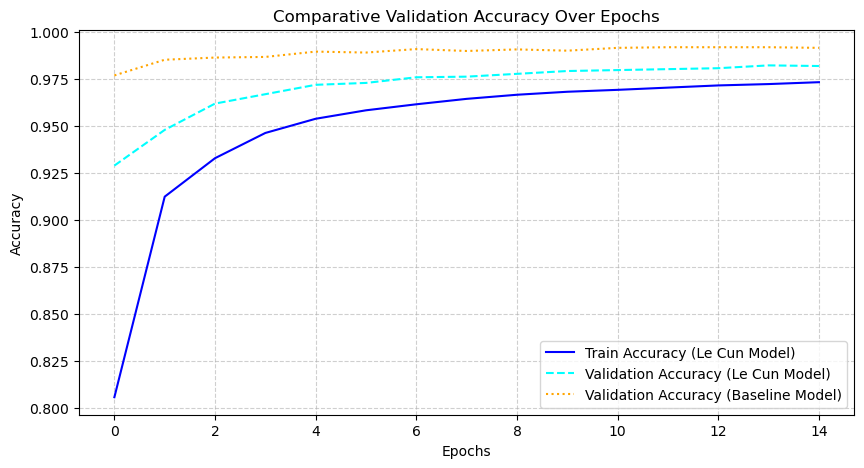

In [6]:
# ==========================================
# 5. VISUALIZATION AND PERFORMANCE EXPORT
# Author's Implementation: Generates comparative accuracy curves and exports high-res graphic.
# ==========================================
plt.figure(figsize=(10, 5))
plt.plot(history_lecun.history['accuracy'], label='Train Accuracy (Le Cun Model)', color='blue')
plt.plot(history_lecun.history['val_accuracy'], label='Validation Accuracy (Le Cun Model)', color='cyan', linestyle='--')
plt.plot(history_baseline.history['val_accuracy'], label='Validation Accuracy (Baseline Model)', color='orange', linestyle=':')
plt.title('Comparative Validation Accuracy Over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.6)

# Save graphic for report insertion
plt.savefig('lecun_training_performance.png', dpi=300, bbox_inches='tight')
plt.show()